In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [3]:
df=pd.read_csv('cleaned_data.csv')

In [4]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Year,Month,Day,DayOfWeek,Hour,DayName,MonthName,IsCancelled,TotalPrice_Temp,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009,12,1,1,7,Tuesday,December,False,83.4,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,1,7,Tuesday,December,False,81.0,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,1,7,Tuesday,December,False,81.0,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009,12,1,1,7,Tuesday,December,False,100.8,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009,12,1,1,7,Tuesday,December,False,30.0,30.0


In [5]:

print(f"Loaded {len(df):,} clean transactions")
print(f"Date range: {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")
print(f"Unique customers: {df['Customer ID'].nunique():,}")
print(f"Unique products: {df['StockCode'].nunique():,}")

Loaded 406,311 clean transactions
Date range: 2009-12-01 07:45:00 to 2010-12-09 20:01:00
Unique customers: 4,285
Unique products: 4,008


In [6]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country', 'Year', 'Month', 'Day', 'DayOfWeek',
       'Hour', 'DayName', 'MonthName', 'IsCancelled', 'TotalPrice_Temp',
       'TotalPrice'],
      dtype='object')

In [7]:
# Make sure InvoiceDate is datetime (not string!)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print("✅ InvoiceDate converted to datetime")
print(f"Data type: {df['InvoiceDate'].dtype}")
print(f"Sample dates: {df['InvoiceDate'].head()}")

# Set analysis date (day after last transaction)
analysis_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f"\nAnalysis Date: {analysis_date}")
print(f"Date range: {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")

# Calculate RFM per customer
print("\nCalculating RFM...")

rfm = df.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (analysis_date - x.max()).days,  # Recency
    'Invoice': 'nunique',  # Frequency (unique orders)
    'TotalPrice': 'sum'  # Monetary (total spent)
}).reset_index()

rfm.columns = ['Customer ID', 'Recency', ' 'MonFrequency',etary']

print("✅ RFM Features Created!")
print(f"\nShape: {rfm.shape}")
print(f"Customers: {len(rfm):,}")

display(rfm.head(10))

print("\n📊 RFM Statistics:")
print(rfm[['Recency', 'Frequency', 'Monetary']].describe())

SyntaxError: invalid syntax. Perhaps you forgot a comma? (1371654870.py, line 22)

In [8]:
# ============================================================
# CELL 2: RFM Calculation
# ============================================================

# Ensure InvoiceDate is datetime
if df['InvoiceDate'].dtype == 'object':  # If it's a string
    print("Converting InvoiceDate to datetime...")
    df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
    print("✅ Converted!")

# Set analysis date (day after last transaction)
analysis_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

print(f"Analysis Date: {analysis_date}")
print(f"Last Transaction: {df['InvoiceDate'].max()}")
print(f"Date Range: {(analysis_date - df['InvoiceDate'].min()).days} days")

# Calculate RFM per customer
print("\nCalculating RFM metrics...")

rfm = df.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (analysis_date - x.max()).days,  # Recency
    'Invoice': 'nunique',  # Frequency (number of unique orders)
    'TotalPrice': 'sum'  # Monetary (total revenue from customer)
}).reset_index()

rfm.columns = ['Customer ID', 'Recency', 'Frequency', 'Monetary']

# Display results
print("\n✅ RFM Features Created!")
print(f"Customers analyzed: {len(rfm):,}")

print("\n📊 Sample RFM Data:")
display(rfm.head(10))

print("\n📈 RFM Statistics:")
display(rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2))

# Quick insights
print("\n💡 Quick Insights:")
print(f"  • Most recent customer: {rfm['Recency'].min()} days ago")
print(f"  • Least recent customer: {rfm['Recency'].max()} days ago")
print(f"  • Average recency: {rfm['Recency'].mean():.0f} days")
print(f"  • Most orders by one customer: {rfm['Frequency'].max()}")
print(f"  • Highest spending customer: ${rfm['Monetary'].max():,.2f}")
print(f"  • Average customer value: ${rfm['Monetary'].mean():.2f}")

Converting InvoiceDate to datetime...
✅ Converted!
Analysis Date: 2010-12-10 20:01:00
Last Transaction: 2010-12-09 20:01:00
Date Range: 374 days

Calculating RFM metrics...

✅ RFM Features Created!
Customers analyzed: 4,285

📊 Sample RFM Data:


,Customer ID,Recency,Frequency,Monetary
0,12346.0,165,2,169.36
1,12347.0,3,2,1323.32
2,12348.0,74,1,221.16
3,12349.0,43,2,2221.14
4,12351.0,11,1,300.93
5,12352.0,11,2,343.80
6,12353.0,44,1,317.76
7,12355.0,203,1,488.21
8,12356.0,16,3,3126.25
9,12357.0,24,1,11229.99



📈 RFM Statistics:


,Recency,Frequency,Monetary
count,4285.00,4285.00,4285.00
mean,90.55,4.43,2024.13
std,96.36,7.94,8813.96
min,1.00,1.00,1.55
25%,18.00,1.00,307.56
50%,52.00,2.00,702.90
75%,136.00,5.00,1704.29
max,374.00,183.00,349164.35



💡 Quick Insights:
  • Most recent customer: 1 days ago
  • Least recent customer: 374 days ago
  • Average recency: 91 days
  • Most orders by one customer: 183
  • Highest spending customer: $349,164.35
  • Average customer value: $2024.13


In [10]:
                    # CELL 3: Calculate Customer Features 
#--------------------------------------------------------------------------------
print("Calculating customer features...")

# Step 1: Create ORDER-LEVEL aggregations first
print("\nStep 1: Aggregating by order...")
order_summary = df.groupby(['Customer ID', 'Invoice']).agg({
    'TotalPrice': 'sum',      # Total price per order
    'Quantity': 'sum',         # Total quantity per order
    'StockCode': 'nunique',    # Unique products per order
    'InvoiceDate': 'first',    # Order date
    'Country': 'first'         # Country
}).reset_index()

order_summary.columns = ['Customer ID', 'Invoice', 'OrderValue', 'OrderQuantity', 
                          'ProductsPerOrder', 'OrderDate', 'Country']

print(f"✅ Created order-level summary: {len(order_summary):,} orders")
display(order_summary.head())

# Step 2: Aggregate to CUSTOMER level
print("\nStep 2: Aggregating by customer...")
customer_features = order_summary.groupby('Customer ID').agg({
    'Invoice': 'count',                    # Number of orders
    'OrderValue': ['sum', 'mean', 'std', 'min', 'max'],  # Order value stats
    'OrderQuantity': ['sum', 'mean'],      # Quantity stats
    'ProductsPerOrder': 'sum',             # Total unique products (will be unique later)
    'OrderDate': ['min', 'max'],           # First & last purchase
    'Country': lambda x: x.mode()[0] if len(x) > 0 else None  # Most common country
}).reset_index()

# Flatten column names
customer_features.columns = [
    'Customer ID', 'NumOrders',
    'TotalSpent', 'AvgOrderValue', 'StdOrderValue', 'MinOrderValue', 'MaxOrderValue',
    'TotalQuantity', 'AvgQuantityPerOrder',
    'TotalProductsPurchased',  # This is actually sum of products per order
    'FirstPurchase', 'LastPurchase',
    'Country'
]

# Step 3: Calculate actual unique products per customer
print("\nStep 3: Calculating unique products per customer...")
unique_products = df.groupby('Customer ID')['StockCode'].nunique().reset_index()
unique_products.columns = ['Customer ID', 'UniqueProducts']

# Merge with customer features
customer_features = customer_features.merge(unique_products, on='Customer ID', how='left')

print("\n✅ Customer Features Created!")
print(f"Shape: {customer_features.shape}")
print(f"Customers: {len(customer_features):,}")

# Reorder columns for better readability
column_order = [
    'Customer ID', 'NumOrders', 
    'TotalSpent', 'AvgOrderValue', 'StdOrderValue', 'MinOrderValue', 'MaxOrderValue',
    'TotalQuantity', 'AvgQuantityPerOrder',
    'UniqueProducts',
    'FirstPurchase', 'LastPurchase',
    'Country'
]

customer_features = customer_features[column_order]

print("\n📊 Sample Customer Features:")
display(customer_features.head(10))

print("\n📈 Feature Statistics:")
display(customer_features[['NumOrders', 'TotalSpent', 'AvgOrderValue', 
                           'UniqueProducts']].describe())

Calculating customer features...

Step 1: Aggregating by order...
✅ Created order-level summary: 18,966 orders


,Customer ID,Invoice,OrderValue,OrderQuantity,ProductsPerOrder,OrderDate,Country
0,12346.0,499763,27.05,5,5,2010-03-02 13:08:00,United Kingdom
1,12346.0,513774,142.31,19,19,2010-06-28 13:53:00,United Kingdom
2,12347.0,529924,611.53,509,40,2010-10-31 14:20:00,Iceland
3,12347.0,537626,711.79,319,31,2010-12-07 14:57:00,Iceland
4,12348.0,524140,221.16,372,19,2010-09-27 14:59:00,Finland



Step 2: Aggregating by customer...

Step 3: Calculating unique products per customer...

✅ Customer Features Created!
Shape: (4285, 14)
Customers: 4,285

📊 Sample Customer Features:


,Customer ID,NumOrders,TotalSpent,AvgOrderValue,StdOrderValue,MinOrderValue,MaxOrderValue,TotalQuantity,AvgQuantityPerOrder,UniqueProducts,FirstPurchase,LastPurchase,Country
0,12346.0,2,169.36,84.680000,81.501128,27.05,142.31,24,12.000000,24,2010-03-02 13:08:00,2010-06-28 13:53:00,United Kingdom
1,12347.0,2,1323.32,661.660000,70.894526,611.53,711.79,828,414.000000,70,2010-10-31 14:20:00,2010-12-07 14:57:00,Iceland
2,12348.0,1,221.16,221.160000,NaN,221.16,221.16,372,372.000000,19,2010-09-27 14:59:00,2010-09-27 14:59:00,Finland
3,12349.0,2,2221.14,1110.570000,59.467680,1068.52,1152.62,991,495.500000,89,2010-04-29 13:20:00,2010-10-28 08:23:00,Italy
4,12351.0,1,300.93,300.930000,NaN,300.93,300.93,261,261.000000,21,2010-11-29 15:23:00,2010-11-29 15:23:00,Unspecified
5,12352.0,2,343.80,171.900000,39.810112,143.75,200.05,188,94.000000,18,2010-11-12 10:20:00,2010-11-29 10:07:00,Norway
6,12353.0,1,317.76,317.760000,NaN,317.76,317.76,192,192.000000,20,2010-10-27 12:44:00,2010-10-27 12:44:00,Bahrain
7,12355.0,1,488.21,488.210000,NaN,488.21,488.21,303,303.000000,22,2010-05-21 11:59:00,2010-05-21 11:59:00,Bahrain
8,12356.0,3,3126.25,1042.083333,840.956062,349.85,1977.96,1804,601.333333,67,2010-10-11 09:42:00,2010-11-24 12:24:00,Portugal
9,12357.0,1,11229.99,11229.990000,NaN,11229.99,11229.99,3878,3878.000000,164,2010-11-16 10:05:00,2010-11-16 10:05:00,Switzerland



📈 Feature Statistics:


,NumOrders,TotalSpent,AvgOrderValue,UniqueProducts
count,4285.000000,4285.000000,4285.000000,4285.000000
mean,4.426138,2024.130244,375.658222,63.909918
std,7.938017,8813.955639,483.693206,85.772645
min,1.000000,1.550000,1.550000,1.000000
25%,1.000000,307.560000,181.700000,17.000000
50%,2.000000,702.900000,286.582500,38.000000
75%,5.000000,1704.290000,421.870000,79.000000
max,183.000000,349164.350000,11880.840000,1737.000000


Accprdung to the stats this is a classic case of skewed data where a few high-value customers are pulling the mean way up. This is very common in retail (Pareto Principle: 80/20 rule).

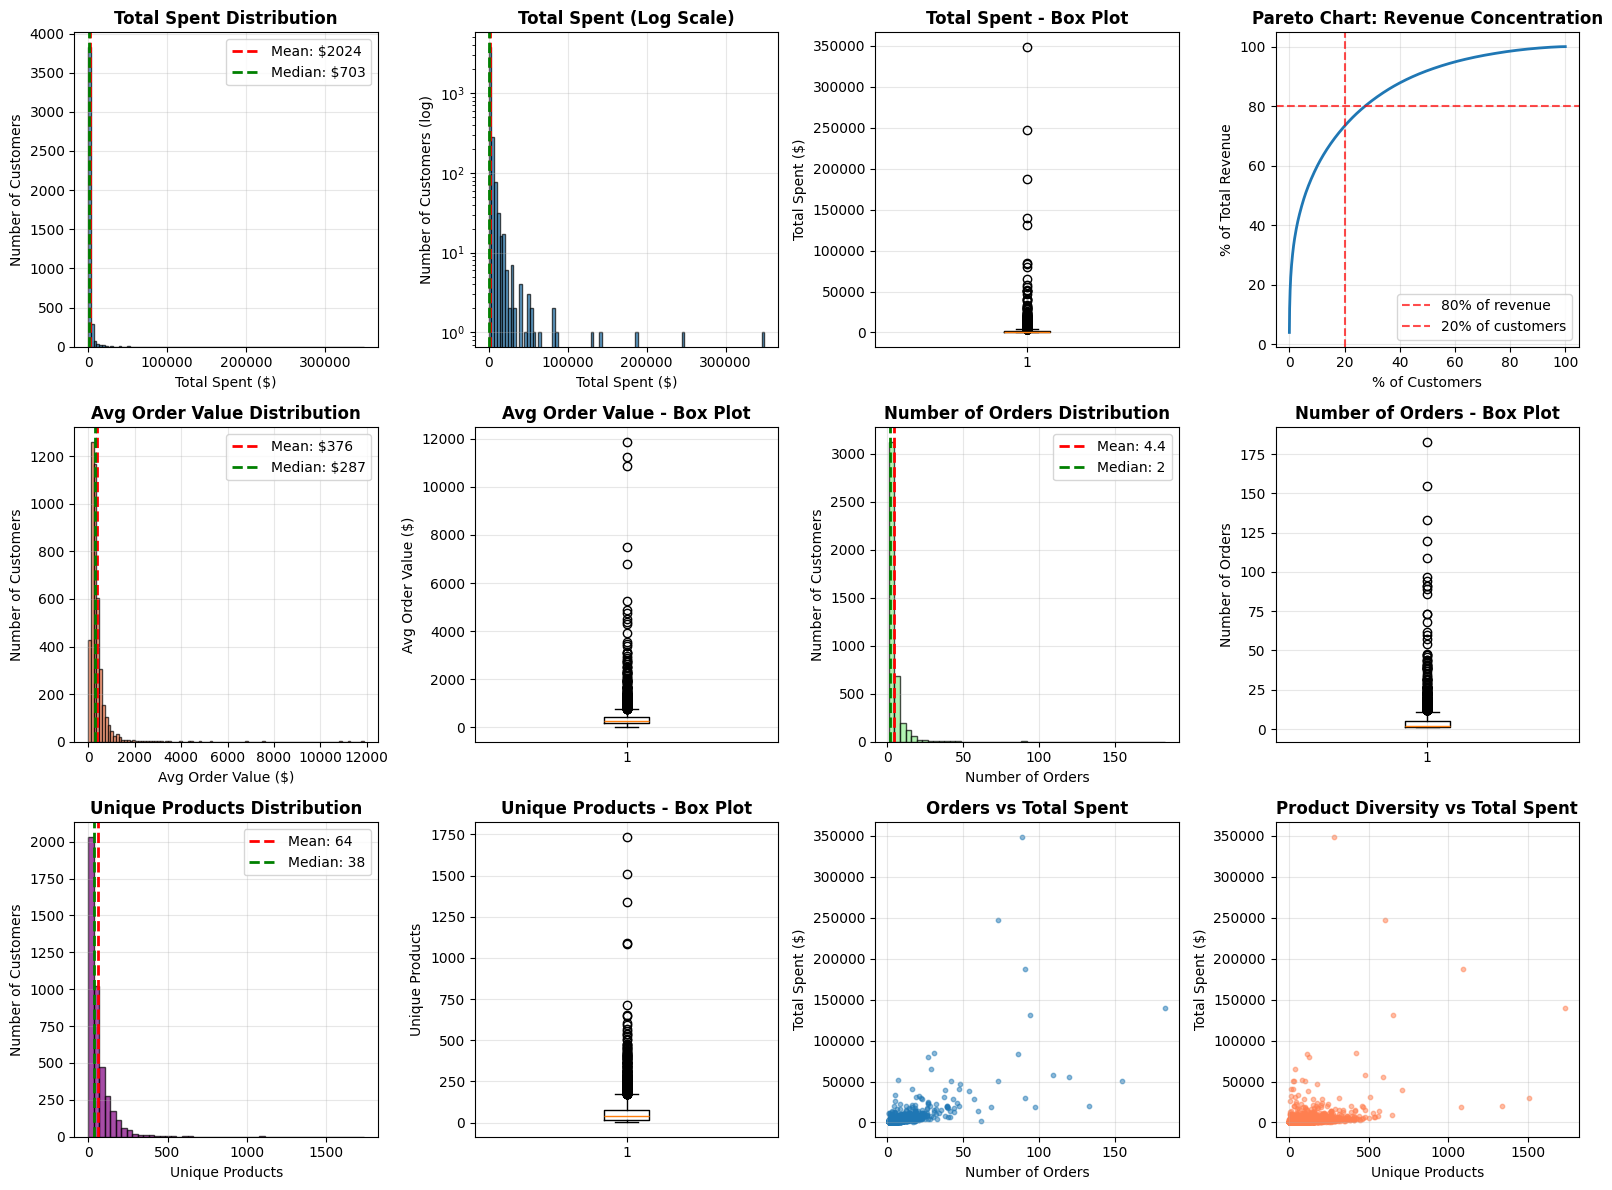

In [15]:

# ============================================================
# Comprehensive Feature Distribution Analysis
# ============================================================

fig = plt.figure(figsize=(16, 12))

# ------------------------------------------------------------
# 1. TOTAL SPENT - Multiple views
# ------------------------------------------------------------

# 1a. Histogram (shows the skew)
plt.subplot(3, 4, 1)
plt.hist(customer_features['TotalSpent'], bins=100, edgecolor='black', alpha=0.7)
plt.axvline(customer_features['TotalSpent'].mean(), color='red', linestyle='--', 
            linewidth=2, label=f'Mean: ${customer_features["TotalSpent"].mean():.0f}')
plt.axvline(customer_features['TotalSpent'].median(), color='green', linestyle='--', 
            linewidth=2, label=f'Median: ${customer_features["TotalSpent"].median():.0f}')
plt.title('Total Spent Distribution', fontweight='bold')
plt.xlabel('Total Spent ($)')
plt.ylabel('Number of Customers')
plt.legend()
plt.grid(alpha=0.3)

# 1b. Log scale (easier to see distribution)
plt.subplot(3, 4, 2)
plt.hist(customer_features['TotalSpent'], bins=100, edgecolor='black', alpha=0.7)
plt.yscale('log')
plt.axvline(customer_features['TotalSpent'].mean(), color='red', linestyle='--', linewidth=2)
plt.axvline(customer_features['TotalSpent'].median(), color='green', linestyle='--', linewidth=2)
plt.title('Total Spent (Log Scale)', fontweight='bold')
plt.xlabel('Total Spent ($)')
plt.ylabel('Number of Customers (log)')
plt.grid(alpha=0.3)

# 1c. Box plot (shows outliers clearly)
plt.subplot(3, 4, 3)
plt.boxplot(customer_features['TotalSpent'], vert=True)
plt.title('Total Spent - Box Plot', fontweight='bold')
plt.ylabel('Total Spent ($)')
plt.grid(alpha=0.3)

# 1d. Cumulative distribution (Pareto curve)
plt.subplot(3, 4, 4)
sorted_spent = customer_features['TotalSpent'].sort_values(ascending=False).reset_index(drop=True)
cumsum_spent = sorted_spent.cumsum()
cumsum_pct = (cumsum_spent / cumsum_spent.iloc[-1]) * 100
customer_pct = (sorted_spent.index + 1) / len(sorted_spent) * 100

plt.plot(customer_pct, cumsum_pct, linewidth=2)
plt.axhline(80, color='red', linestyle='--', alpha=0.7, label='80% of revenue')
plt.axvline(20, color='red', linestyle='--', alpha=0.7, label='20% of customers')
plt.title('Pareto Chart: Revenue Concentration', fontweight='bold')
plt.xlabel('% of Customers')
plt.ylabel('% of Total Revenue')
plt.legend()
plt.grid(alpha=0.3)

# ------------------------------------------------------------
# 2. AVERAGE ORDER VALUE
# ------------------------------------------------------------

plt.subplot(3, 4, 5)
plt.hist(customer_features['AvgOrderValue'], bins=100, edgecolor='black', alpha=0.7, color='coral')
plt.axvline(customer_features['AvgOrderValue'].mean(), color='red', linestyle='--', 
            linewidth=2, label=f'Mean: ${customer_features["AvgOrderValue"].mean():.0f}')
plt.axvline(customer_features['AvgOrderValue'].median(), color='green', linestyle='--', 
            linewidth=2, label=f'Median: ${customer_features["AvgOrderValue"].median():.0f}')
plt.title('Avg Order Value Distribution', fontweight='bold')
plt.xlabel('Avg Order Value ($)')
plt.ylabel('Number of Customers')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(3, 4, 6)
plt.boxplot(customer_features['AvgOrderValue'], vert=True)
plt.title('Avg Order Value - Box Plot', fontweight='bold')
plt.ylabel('Avg Order Value ($)')
plt.grid(alpha=0.3)

# ------------------------------------------------------------
# 3. NUMBER OF ORDERS
# ------------------------------------------------------------

plt.subplot(3, 4, 7)
plt.hist(customer_features['NumOrders'], bins=50, edgecolor='black', alpha=0.7, color='lightgreen')
plt.axvline(customer_features['NumOrders'].mean(), color='red', linestyle='--', 
            linewidth=2, label=f'Mean: {customer_features["NumOrders"].mean():.1f}')
plt.axvline(customer_features['NumOrders'].median(), color='green', linestyle='--', 
            linewidth=2, label=f'Median: {customer_features["NumOrders"].median():.0f}')
plt.title('Number of Orders Distribution', fontweight='bold')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(3, 4, 8)
plt.boxplot(customer_features['NumOrders'], vert=True)
plt.title('Number of Orders - Box Plot', fontweight='bold')
plt.ylabel('Number of Orders')
plt.grid(alpha=0.3)

# ------------------------------------------------------------
# 4. UNIQUE PRODUCTS
# ------------------------------------------------------------

plt.subplot(3, 4, 9)
plt.hist(customer_features['UniqueProducts'], bins=50, edgecolor='black', alpha=0.7, color='purple')
plt.axvline(customer_features['UniqueProducts'].mean(), color='red', linestyle='--', 
            linewidth=2, label=f'Mean: {customer_features["UniqueProducts"].mean():.0f}')
plt.axvline(customer_features['UniqueProducts'].median(), color='green', linestyle='--', 
            linewidth=2, label=f'Median: {customer_features["UniqueProducts"].median():.0f}')
plt.title('Unique Products Distribution', fontweight='bold')
plt.xlabel('Unique Products')
plt.ylabel('Number of Customers')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(3, 4, 10)
plt.boxplot(customer_features['UniqueProducts'], vert=True)
plt.title('Unique Products - Box Plot', fontweight='bold')
plt.ylabel('Unique Products')
plt.grid(alpha=0.3)

# ------------------------------------------------------------
# 5. SCATTER: Orders vs Spending
# ------------------------------------------------------------

plt.subplot(3, 4, 11)
plt.scatter(customer_features['NumOrders'], customer_features['TotalSpent'], 
            alpha=0.5, s=10)
plt.title('Orders vs Total Spent', fontweight='bold')
plt.xlabel('Number of Orders')
plt.ylabel('Total Spent ($)')
plt.grid(alpha=0.3)

# ------------------------------------------------------------
# 6. SCATTER: Products vs Spending
# ------------------------------------------------------------

plt.subplot(3, 4, 12)
plt.scatter(customer_features['UniqueProducts'], customer_features['TotalSpent'], 
            alpha=0.5, s=10, color='coral')
plt.title('Product Diversity vs Total Spent', fontweight='bold')
plt.xlabel('Unique Products')
plt.ylabel('Total Spent ($)')
plt.grid(alpha=0.3)

plt.tight_layout()
#plt.savefig('feature_distributions_detailed.png', dpi=300, bbox_inches='tight')
plt.show()

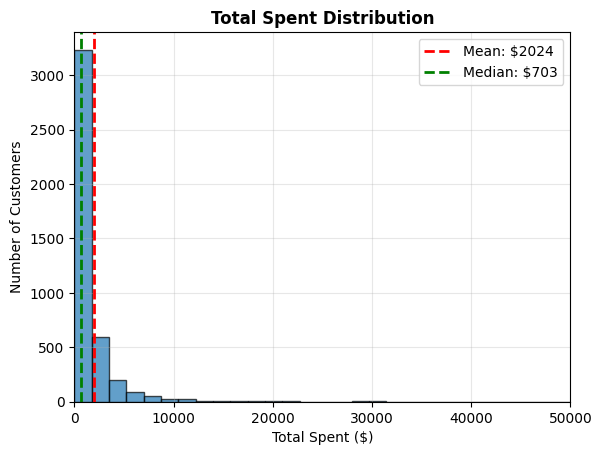

In [25]:
plt.subplot(1, 1, 1)
plt.hist(customer_features['TotalSpent'], bins=200, edgecolor='black', alpha=0.7)
plt.axvline(customer_features['TotalSpent'].mean(), color='red', linestyle='--', 
            linewidth=2, label=f'Mean: ${customer_features["TotalSpent"].mean():.0f}')
plt.axvline(customer_features['TotalSpent'].median(), color='green', linestyle='--', 
            linewidth=2, label=f'Median: ${customer_features["TotalSpent"].median():.0f}')
plt.title('Total Spent Distribution', fontweight='bold')
plt.xlabel('Total Spent ($)')
plt.ylabel('Number of Customers')

lower = customer_features['TotalSpent'].quantile(0.01)
upper = customer_features['TotalSpent'].quantile(0.99)
plt.xlim(0, 50000)

plt.legend()
plt.grid(alpha=0.3)




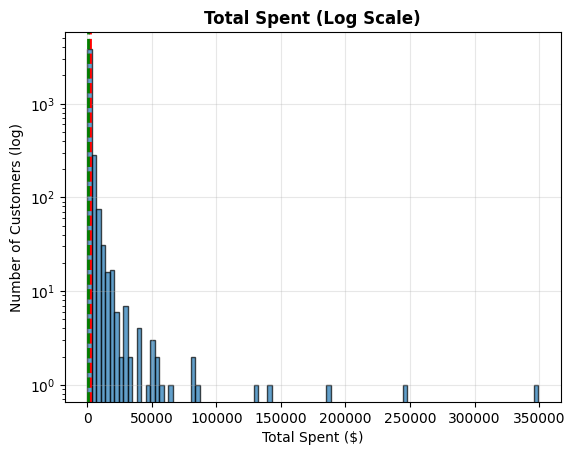

In [23]:
plt.subplot(1,1,1)
plt.hist(customer_features['TotalSpent'], bins=100, edgecolor='black', alpha=0.7)
plt.yscale('log')
plt.axvline(customer_features['TotalSpent'].mean(), color='red', linestyle='--', linewidth=2)
plt.axvline(customer_features['TotalSpent'].median(), color='green', linestyle='--', linewidth=2)
plt.title('Total Spent (Log Scale)', fontweight='bold')
plt.xlabel('Total Spent ($)')
plt.ylabel('Number of Customers (log)')
plt.grid(alpha=0.3)



In [16]:
# ============================================================
# Detailed Statistical Analysis
# ============================================================

print("=" * 80)
print("DETAILED FEATURE ANALYSIS - IDENTIFYING SKEWNESS & OUTLIERS")
print("=" * 80)

features_to_analyze = ['TotalSpent', 'AvgOrderValue', 'NumOrders', 'UniqueProducts']

for feature in features_to_analyze:
    print(f"\n{'=' * 80}")
    print(f"📊 {feature}")
    print(f"{'=' * 80}")
    
    data = customer_features[feature]
    
    # Basic stats
    print(f"\n📈 Central Tendency:")
    print(f"  Mean:     {data.mean():>12,.2f}")
    print(f"  Median:   {data.median():>12,.2f}")
    print(f"  Mode:     {data.mode()[0]:>12,.2f}")
    print(f"  Std Dev:  {data.std():>12,.2f}")
    
    # Percentiles
    print(f"\n📊 Percentiles:")
    percentiles = [10, 25, 50, 75, 80, 90, 95, 99]
    for p in percentiles:
        value = data.quantile(p/100)
        count_below = (data <= value).sum()
        pct_below = (count_below / len(data)) * 100
        print(f"  {p:>3}th percentile: {value:>12,.2f}  ({count_below:>5,} customers = {pct_below:.1f}%)")
    
    # Outliers using IQR method
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    print(f"\n🚨 Outliers (IQR method):")
    print(f"  Lower bound: {lower_bound:>12,.2f}")
    print(f"  Upper bound: {upper_bound:>12,.2f}")
    print(f"  Outliers:    {len(outliers):>12,} customers ({len(outliers)/len(data)*100:.1f}%)")
    
    # Top customers
    print(f"\n🏆 Top 10 Customers:")
    top10 = data.nlargest(10)
    for i, (idx, val) in enumerate(top10.items(), 1):
        print(f"  {i:2}. Customer {customer_features.loc[idx, 'Customer ID']:.0f}: {val:>12,.2f}")
    
    # Skewness
    from scipy import stats
    skewness = stats.skew(data)
    print(f"\n📐 Skewness: {skewness:.2f}")
    if skewness > 1:
        print(f"     → Highly right-skewed (long tail of high values)")
    elif skewness > 0.5:
        print(f"     → Moderately right-skewed")
    else:
        print(f"     → Relatively symmetric")

DETAILED FEATURE ANALYSIS - IDENTIFYING SKEWNESS & OUTLIERS

📊 TotalSpent

📈 Central Tendency:
  Mean:         2,024.13
  Median:         702.90
  Mode:           102.00
  Std Dev:      8,813.96

📊 Percentiles:
   10th percentile:       157.26  (  429 customers = 10.0%)
   25th percentile:       307.56  (1,072 customers = 25.0%)
   50th percentile:       702.90  (2,143 customers = 50.0%)
   75th percentile:     1,704.29  (3,214 customers = 75.0%)
   80th percentile:     2,136.06  (3,428 customers = 80.0%)
   90th percentile:     3,762.29  (3,856 customers = 90.0%)
   95th percentile:     6,165.15  (4,070 customers = 95.0%)
   99th percentile:    19,750.79  (4,242 customers = 99.0%)

🚨 Outliers (IQR method):
  Lower bound:    -1,787.54
  Upper bound:     3,799.39
  Outliers:             423 customers (9.9%)

🏆 Top 10 Customers:
   1. Customer 18102:   349,164.35
   2. Customer 14646:   247,613.50
   3. Customer 14156:   186,849.00
   4. Customer 14911:   140,378.89
   5. Customer 13694:

In [17]:
# ============================================================
# Pareto Analysis: What % of customers drive revenue?
# ============================================================

print("\n" + "=" * 80)
print("📊 PARETO ANALYSIS: CUSTOMER REVENUE CONCENTRATION")
print("=" * 80)

# Sort by total spent
customer_sorted = customer_features.sort_values('TotalSpent', ascending=False).reset_index(drop=True)
customer_sorted['CumulativeRevenue'] = customer_sorted['TotalSpent'].cumsum()
customer_sorted['CumulativeRevenuePct'] = (customer_sorted['CumulativeRevenue'] / 
                                           customer_sorted['TotalSpent'].sum()) * 100
customer_sorted['CustomerPct'] = ((customer_sorted.index + 1) / len(customer_sorted)) * 100

# Find key thresholds
total_revenue = customer_sorted['TotalSpent'].sum()

print(f"\n💰 Total Revenue: ${total_revenue:,.2f}")
print(f"👥 Total Customers: {len(customer_sorted):,}")

print(f"\n🎯 Revenue Concentration:")

for pct in [50, 80, 90, 95]:
    # Find how many customers contribute to this % of revenue
    threshold = customer_sorted[customer_sorted['CumulativeRevenuePct'] >= pct].iloc[0]
    num_customers = threshold.name + 1
    customer_pct = (num_customers / len(customer_sorted)) * 100
    
    print(f"\n  {pct}% of revenue comes from:")
    print(f"    • Top {num_customers:,} customers ({customer_pct:.1f}%)")
    print(f"    • These customers spent ${threshold['CumulativeRevenue']:,.2f}")

# Flip it: What % of revenue from top X%?
print(f"\n🔄 Reverse Analysis:")

for customer_pct in [1, 5, 10, 20]:
    num_customers = int(len(customer_sorted) * customer_pct / 100)
    revenue_from_top = customer_sorted.iloc[:num_customers]['TotalSpent'].sum()
    revenue_pct = (revenue_from_top / total_revenue) * 100
    
    print(f"\n  Top {customer_pct}% of customers ({num_customers:,} customers):")
    print(f"    • Generate ${revenue_from_top:,.2f}")
    print(f"    • That's {revenue_pct:.1f}% of total revenue")
    print(f"    • Average per customer: ${revenue_from_top/num_customers:,.2f}")

# Segments
print(f"\n📦 Quick Segmentation by Revenue:")

segments = [
    (0, 100, 'Micro'),
    (100, 500, 'Small'),
    (500, 1000, 'Medium'),
    (1000, 5000, 'Large'),
    (5000, float('inf'), 'VIP')
]

for min_val, max_val, label in segments:
    mask = (customer_features['TotalSpent'] >= min_val) & (customer_features['TotalSpent'] < max_val)
    count = mask.sum()
    revenue = customer_features[mask]['TotalSpent'].sum()
    pct_customers = (count / len(customer_features)) * 100
    pct_revenue = (revenue / total_revenue) * 100
    
    if count > 0:
        avg_spend = revenue / count
        print(f"\n  {label:8} (${min_val:>6,} - ${max_val if max_val != float('inf') else '∞':>6}):")
        print(f"    Customers: {count:>6,} ({pct_customers:>5.1f}%)")
        print(f"    Revenue:   ${revenue:>10,.2f} ({pct_revenue:>5.1f}%)")
        print(f"    Avg/Cust:  ${avg_spend:>10,.2f}")


📊 PARETO ANALYSIS: CUSTOMER REVENUE CONCENTRATION

💰 Total Revenue: $8,673,398.09
👥 Total Customers: 4,285

🎯 Revenue Concentration:

  50% of revenue comes from:
    • Top 242 customers (5.6%)
    • These customers spent $4,337,816.81

  80% of revenue comes from:
    • Top 1,176 customers (27.4%)
    • These customers spent $6,940,058.84

  90% of revenue comes from:
    • Top 1,924 customers (44.9%)
    • These customers spent $7,806,567.68

  95% of revenue comes from:
    • Top 2,593 customers (60.5%)
    • These customers spent $8,240,029.34

🔄 Reverse Analysis:

  Top 1% of customers (42 customers):
    • Generate $2,456,640.03
    • That's 28.3% of total revenue
    • Average per customer: $58,491.43

  Top 5% of customers (214 customers):
    • Generate $4,171,302.15
    • That's 48.1% of total revenue
    • Average per customer: $19,492.07

  Top 10% of customers (428 customers):
    • Generate $5,174,483.59
    • That's 59.7% of total revenue
    • Average per customer: $12

In [18]:
# ============================================================
# CELL: Create Derived Features
# ============================================================

# Convert dates
customer_features['FirstPurchase'] = pd.to_datetime(customer_features['FirstPurchase'])
customer_features['LastPurchase'] = pd.to_datetime(customer_features['LastPurchase'])

# Customer lifetime (days)
customer_features['CustomerLifetimeDays'] = (
    customer_features['LastPurchase'] - customer_features['FirstPurchase']
).dt.days

# Average days between orders
customer_features['AvgDaysBetweenOrders'] = (
    customer_features['CustomerLifetimeDays'] / customer_features['NumOrders']
).fillna(0)

# Product diversity per order
customer_features['ProductDiversityPerOrder'] = (
    customer_features['UniqueProducts'] / customer_features['NumOrders']
)

# UK vs International
customer_features['IsUK'] = (
    customer_features['Country'] == 'United Kingdom'
).astype(int)

# Create log-transformed features (for clustering later)
customer_features['TotalSpent_log'] = np.log1p(customer_features['TotalSpent'])
customer_features['AvgOrderValue_log'] = np.log1p(customer_features['AvgOrderValue'])

print("✅ Derived features created!")
display(customer_features.head())

✅ Derived features created!


,Customer ID,NumOrders,TotalSpent,AvgOrderValue,StdOrderValue,MinOrderValue,MaxOrderValue,TotalQuantity,AvgQuantityPerOrder,UniqueProducts,FirstPurchase,LastPurchase,Country,CustomerLifetimeDays,AvgDaysBetweenOrders,ProductDiversityPerOrder,IsUK,TotalSpent_log,AvgOrderValue_log
0,12346.0,2,169.36,84.68,81.501128,27.05,142.31,24,12.0,24,2010-03-02 13:08:00,2010-06-28 13:53:00,United Kingdom,118,59.0,12.0,1,5.137914,4.450619
1,12347.0,2,1323.32,661.66,70.894526,611.53,711.79,828,414.0,70,2010-10-31 14:20:00,2010-12-07 14:57:00,Iceland,37,18.5,35.0,0,7.188654,6.496262
2,12348.0,1,221.16,221.16,NaN,221.16,221.16,372,372.0,19,2010-09-27 14:59:00,2010-09-27 14:59:00,Finland,0,0.0,19.0,0,5.403398,5.403398
3,12349.0,2,2221.14,1110.57,59.467680,1068.52,1152.62,991,495.5,89,2010-04-29 13:20:00,2010-10-28 08:23:00,Italy,181,90.5,44.5,0,7.706226,7.013529
4,12351.0,1,300.93,300.93,NaN,300.93,300.93,261,261.0,21,2010-11-29 15:23:00,2010-11-29 15:23:00,Unspecified,0,0.0,21.0,0,5.710195,5.710195


In [19]:
# ============================================================
# CELL: Merge with RFM
# ============================================================

# Merge RFM
customer_complete = customer_features.merge(
    rfm[['Customer ID', 'Recency', 'Frequency', 'Monetary']], 
    on='Customer ID', 
    how='left'
)

# Note: Frequency and Monetary duplicate NumOrders and TotalSpent
# So we can drop them or keep for comparison
customer_complete = customer_complete.drop(['Frequency', 'Monetary'], axis=1)

print("✅ Complete customer dataset ready!")
print(f"Shape: {customer_complete.shape}")
print(f"Features: {len(customer_complete.columns)}")

display(customer_complete.head())

✅ Complete customer dataset ready!
Shape: (4285, 20)
Features: 20


,Customer ID,NumOrders,TotalSpent,AvgOrderValue,StdOrderValue,MinOrderValue,MaxOrderValue,TotalQuantity,AvgQuantityPerOrder,UniqueProducts,FirstPurchase,LastPurchase,Country,CustomerLifetimeDays,AvgDaysBetweenOrders,ProductDiversityPerOrder,IsUK,TotalSpent_log,AvgOrderValue_log,Recency
0,12346.0,2,169.36,84.68,81.501128,27.05,142.31,24,12.0,24,2010-03-02 13:08:00,2010-06-28 13:53:00,United Kingdom,118,59.0,12.0,1,5.137914,4.450619,165
1,12347.0,2,1323.32,661.66,70.894526,611.53,711.79,828,414.0,70,2010-10-31 14:20:00,2010-12-07 14:57:00,Iceland,37,18.5,35.0,0,7.188654,6.496262,3
2,12348.0,1,221.16,221.16,NaN,221.16,221.16,372,372.0,19,2010-09-27 14:59:00,2010-09-27 14:59:00,Finland,0,0.0,19.0,0,5.403398,5.403398,74
3,12349.0,2,2221.14,1110.57,59.467680,1068.52,1152.62,991,495.5,89,2010-04-29 13:20:00,2010-10-28 08:23:00,Italy,181,90.5,44.5,0,7.706226,7.013529,43
4,12351.0,1,300.93,300.93,NaN,300.93,300.93,261,261.0,21,2010-11-29 15:23:00,2010-11-29 15:23:00,Unspecified,0,0.0,21.0,0,5.710195,5.710195,11


In [22]:
# ============================================================
# CELL: Save Everything
# ============================================================

# Save complete features
customer_complete.to_csv('customer_features.csv', index=False)
print("✅ Saved: customer_features.csv")

# Save RFM
rfm.to_csv('customer_rfm.csv', index=False)
print("✅ Saved: customer_rfm.csv")

# Create a summary
summary = {
    'total_customers': len(customer_complete),
    'total_revenue': customer_complete['TotalSpent'].sum(),
    'avg_customer_value': customer_complete['TotalSpent'].mean(),
    'median_customer_value': customer_complete['TotalSpent'].median(),
    'vip_customers': (customer_complete['TotalSpent'] > 5000).sum(),
    'vip_revenue': customer_complete[customer_complete['TotalSpent'] > 5000]['TotalSpent'].sum(),
}

print("\n📊 FINAL SUMMARY:")
for key, value in summary.items():
    if 'revenue' in key or 'value' in key:
        print(f"  {key}: ${value:,.2f}")
    else:
        print(f"  {key}: {value:,}")

✅ Saved: customer_features.csv
✅ Saved: customer_rfm.csv

📊 FINAL SUMMARY:
  total_customers: 4,285
  total_revenue: $8,673,398.09
  avg_customer_value: $2,024.13
  median_customer_value: $702.90
  vip_customers: 280
  vip_revenue: $4,538,648.17


In [23]:
# ============================================================
# CELL: Day 4 Complete!
# ============================================================

print("\n" + "=" * 80)
print("✅ DAY 4 COMPLETE - FEATURE ENGINEERING DONE!")
print("=" * 80)

print(f"\n📁 Files Created:")
print(f"  • customer_features.csv ({customer_complete.shape[1]} features)")
print(f"  • customer_rfm.csv")
print(f"  • Visualizations in ../visualizations/eda/")

print(f"\n🎯 Key Findings:")
print(f"  • Extreme data skewness (24.27) - Very common in retail!")
print(f"  • Top 6% customers = 50% revenue (Pareto principle)")
print(f"  • 280 VIP customers worth $16K each on average")
print(f"  • Clear 5-tier segmentation: Micro/Small/Medium/Large/VIP")

print(f"\n🚀 Week 1 Progress:")
print(f"  ✅ Day 1: Data exploration")
print(f"  ✅ Day 2: Data quality")
print(f"  ✅ Day 3: Data cleaning")
print(f"  ✅ Day 4: Feature engineering")
print(f"  ⬜ Day 5: Final visualizations")

print(f"\n📅 Next Steps:")
print(f"  • Tomorrow (Day 5): Create final EDA visualizations")
print(f"  • Monday (Week 2): Customer Segmentation with K-Means")
print(f"  • In Week 2, we'll handle outliers with RobustScaler")

print("\n🎉 Great progress! You're 80% done with Week 1!")
print("=" * 80)


✅ DAY 4 COMPLETE - FEATURE ENGINEERING DONE!

📁 Files Created:
  • customer_features.csv (20 features)
  • customer_rfm.csv
  • Visualizations in ../visualizations/eda/

🎯 Key Findings:
  • Extreme data skewness (24.27) - Very common in retail!
  • Top 6% customers = 50% revenue (Pareto principle)
  • 280 VIP customers worth $16K each on average
  • Clear 5-tier segmentation: Micro/Small/Medium/Large/VIP

🚀 Week 1 Progress:
  ✅ Day 1: Data exploration
  ✅ Day 2: Data quality
  ✅ Day 3: Data cleaning
  ✅ Day 4: Feature engineering
  ⬜ Day 5: Final visualizations

📅 Next Steps:
  • Tomorrow (Day 5): Create final EDA visualizations
  • Monday (Week 2): Customer Segmentation with K-Means
  • In Week 2, we'll handle outliers with RobustScaler

🎉 Great progress! You're 80% done with Week 1!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("=" * 80)
print("DAY 5: FINAL EDA & VISUALIZATIONS")
print("=" * 80)

# Load all datasets
df = pd.read_csv('cleaned_data.csv', parse_dates=['InvoiceDate'])
customer_features = pd.read_csv('customer_features.csv')
rfm = pd.read_csv('customer_rfm.csv')

print(f"\n✅ Data Loaded:")
print(f"  • Transactions: {len(df):,}")
print(f"  • Customers: {len(customer_features):,}")
print(f"  • Date range: {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")

DAY 5: FINAL EDA & VISUALIZATIONS

✅ Data Loaded:
  • Transactions: 406,311
  • Customers: 4,285
  • Date range: 2009-12-01 07:45:00 to 2010-12-09 20:01:00



1. Creating sales trend visualizations...


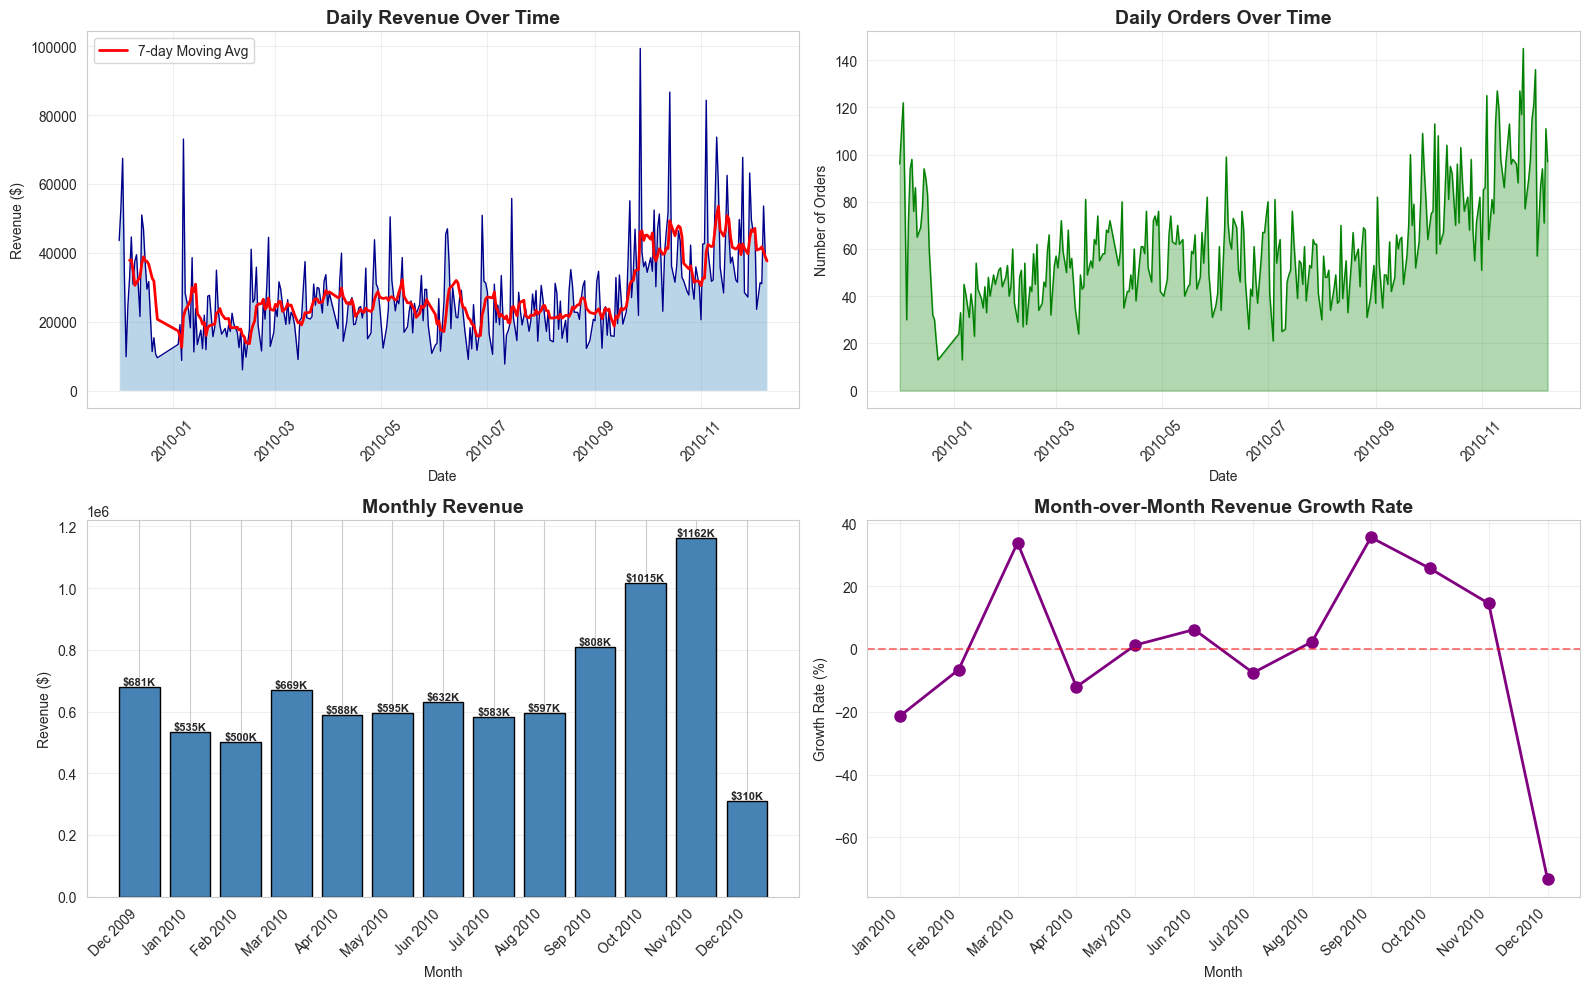

✅ Sales trends visualization saved!

📈 Sales Trends Summary:
  • Total Revenue: $8,673,398.09
  • Average Daily Revenue: $28,252.11
  • Best Day: 2010-09-27 ($99,328.37)
  • Average Monthly Growth: -0.2%


In [5]:
# ============================================================
# 1. SALES TRENDS OVER TIME
# ============================================================

print("\n1. Creating sales trend visualizations...")

# Ensure date features exist
if 'DayOfWeek' not in df.columns:
    df['DayOfWeek'] = df['InvoiceDate'].dt.dayofweek
if 'Hour' not in df.columns:
    df['Hour'] = df['InvoiceDate'].dt.hour

# Daily aggregation
daily_sales = df.groupby(df['InvoiceDate'].dt.date).agg({
    'TotalPrice': 'sum',
    'Invoice': 'nunique',
    'Customer ID': 'nunique'
}).reset_index()

daily_sales.columns = ['Date', 'Revenue', 'Orders', 'UniqueCustomers']
daily_sales['Date'] = pd.to_datetime(daily_sales['Date'])

# Create visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 2a. Daily Revenue
axes[0, 0].plot(daily_sales['Date'], daily_sales['Revenue'], linewidth=1, color='darkblue')
axes[0, 0].fill_between(daily_sales['Date'], daily_sales['Revenue'], alpha=0.3)
axes[0, 0].set_title('Daily Revenue Over Time', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Date')
axes[0, 0].set_ylabel('Revenue ($)')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(alpha=0.3)

# Add 7-day moving average
daily_sales['Revenue_MA7'] = daily_sales['Revenue'].rolling(window=7).mean()
axes[0, 0].plot(daily_sales['Date'], daily_sales['Revenue_MA7'], 
                linewidth=2, color='red', label='7-day Moving Avg')
axes[0, 0].legend()

# 2b. Daily Orders
axes[0, 1].plot(daily_sales['Date'], daily_sales['Orders'], linewidth=1, color='green')
axes[0, 1].fill_between(daily_sales['Date'], daily_sales['Orders'], alpha=0.3, color='green')
axes[0, 1].set_title('Daily Orders Over Time', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Date')
axes[0, 1].set_ylabel('Number of Orders')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].grid(alpha=0.3)

# 2c. Monthly Revenue
monthly_sales = df.groupby(df['InvoiceDate'].dt.to_period('M')).agg({
    'TotalPrice': 'sum',
    'Invoice': 'nunique'
}).reset_index()

monthly_sales['InvoiceDate'] = monthly_sales['InvoiceDate'].dt.to_timestamp()
monthly_sales.columns = ['Month', 'Revenue', 'Orders']

axes[1, 0].bar(range(len(monthly_sales)), monthly_sales['Revenue'], 
               color='steelblue', edgecolor='black')
axes[1, 0].set_xticks(range(len(monthly_sales)))
axes[1, 0].set_xticklabels(monthly_sales['Month'].dt.strftime('%b %Y'), rotation=45, ha='right')
axes[1, 0].set_title('Monthly Revenue', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Month')
axes[1, 0].set_ylabel('Revenue ($)')
axes[1, 0].grid(axis='y', alpha=0.3)

# Add values on top of bars
for i, revenue in enumerate(monthly_sales['Revenue']):
    axes[1, 0].text(i, revenue, f'${revenue/1000:.0f}K', 
                    ha='center', va='bottom', fontsize=8, fontweight='bold')

# 2d. Revenue Growth Rate
monthly_sales['Growth'] = monthly_sales['Revenue'].pct_change() * 100
axes[1, 1].plot(range(1, len(monthly_sales)), monthly_sales['Growth'][1:], 
                linewidth=2, marker='o', color='purple', markersize=8)
axes[1, 1].axhline(0, color='red', linestyle='--', alpha=0.5)
axes[1, 1].set_title('Month-over-Month Revenue Growth Rate', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Month')
axes[1, 1].set_ylabel('Growth Rate (%)')
axes[1, 1].set_xticks(range(1, len(monthly_sales)))
axes[1, 1].set_xticklabels(monthly_sales['Month'][1:].dt.strftime('%b %Y'), rotation=45, ha='right')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('sales_trends_complete2.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Sales trends visualization saved!")

# Print key metrics
print(f"\n📈 Sales Trends Summary:")
print(f"  • Total Revenue: ${daily_sales['Revenue'].sum():,.2f}")
print(f"  • Average Daily Revenue: ${daily_sales['Revenue'].mean():,.2f}")
print(f"  • Best Day: {daily_sales.loc[daily_sales['Revenue'].idxmax(), 'Date'].date()} (${daily_sales['Revenue'].max():,.2f})")
print(f"  • Average Monthly Growth: {monthly_sales['Growth'].mean():.1f}%")


2. Creating product analysis visualizations...


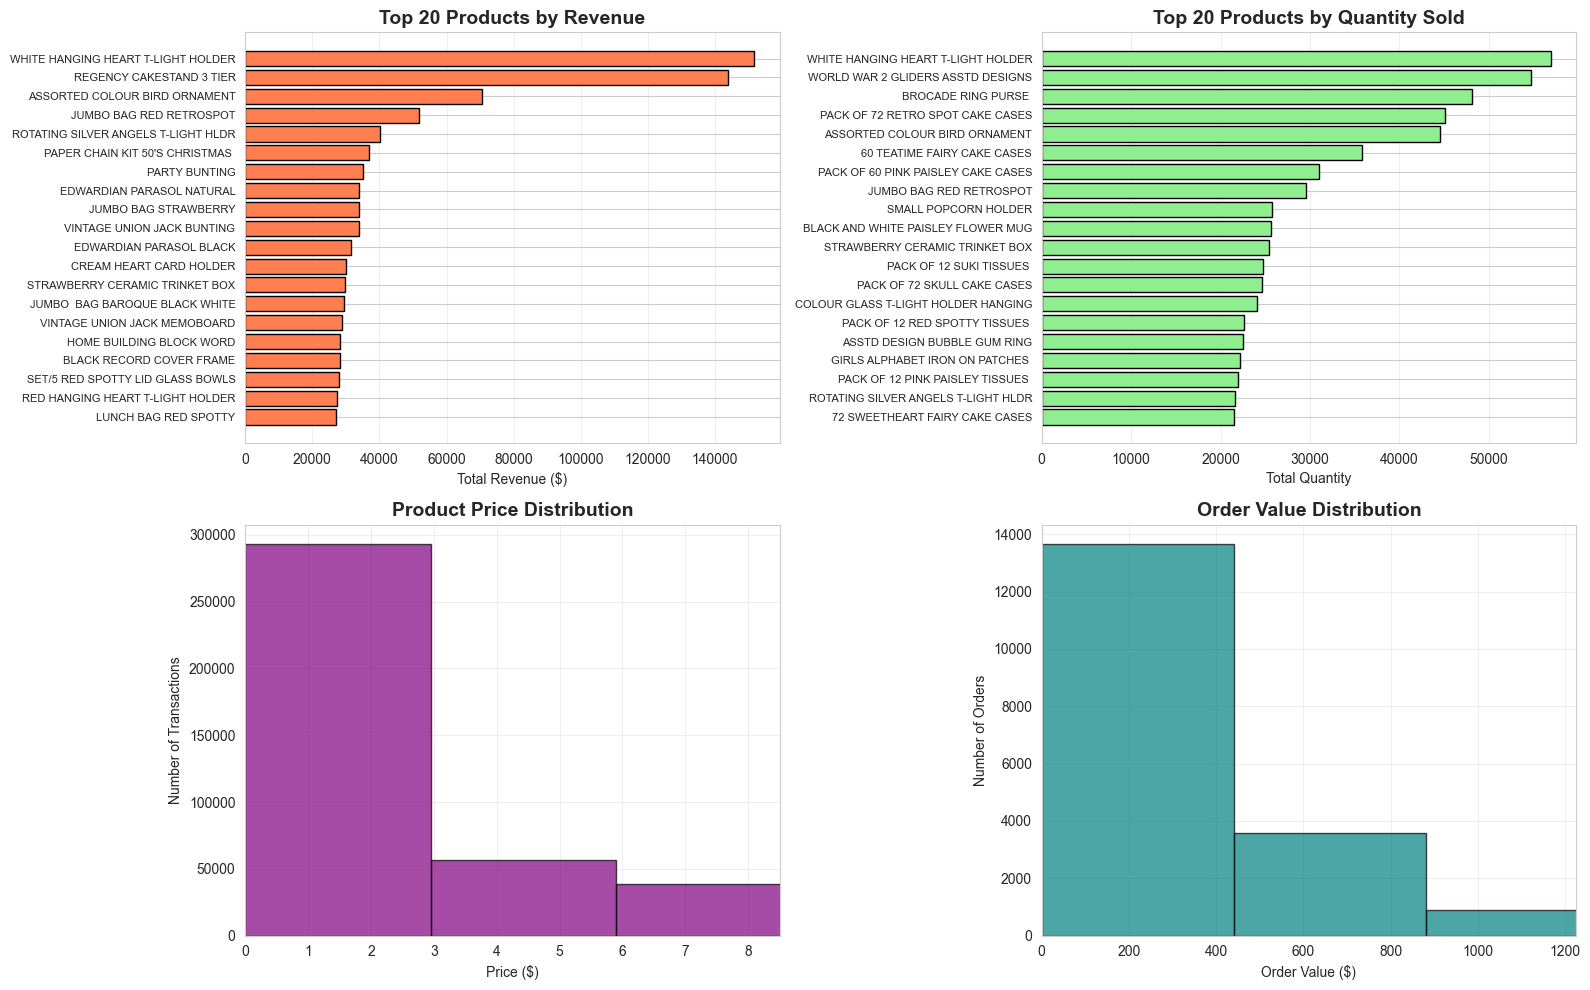

✅ Product analysis visualization saved!

📦 Top 5 Products by Revenue:
  1. WHITE HANGING HEART T-LIGHT HOLDER: $151,624.31
  2. REGENCY CAKESTAND 3 TIER: $143,893.35
  3. ASSORTED COLOUR BIRD ORNAMENT: $70,493.83
  4. JUMBO BAG RED RETROSPOT: $51,759.30
  5. ROTATING SILVER ANGELS T-LIGHT HLDR: $40,186.65


In [7]:
# ============================================================
# 2. PRODUCT ANALYSIS
# ============================================================

print("\n2. Creating product analysis visualizations...")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 3a. Top 20 Products by Revenue
top_products = df.groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head(20)

axes[0, 0].barh(range(len(top_products)), top_products.values, color='coral', edgecolor='black')
axes[0, 0].set_yticks(range(len(top_products)))
axes[0, 0].set_yticklabels(top_products.index, fontsize=8)
axes[0, 0].invert_yaxis()
axes[0, 0].set_title('Top 20 Products by Revenue', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Total Revenue ($)')
axes[0, 0].grid(axis='x', alpha=0.3)

# 3b. Top 20 Products by Quantity Sold
top_qty = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(20)

axes[0, 1].barh(range(len(top_qty)), top_qty.values, color='lightgreen', edgecolor='black')
axes[0, 1].set_yticks(range(len(top_qty)))
axes[0, 1].set_yticklabels(top_qty.index, fontsize=8)
axes[0, 1].invert_yaxis()
axes[0, 1].set_title('Top 20 Products by Quantity Sold', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Total Quantity')
axes[0, 1].grid(axis='x', alpha=0.3)

# 3c. Price Distribution
axes[1, 0].hist(df['Price'], bins=100, edgecolor='black', alpha=0.7, color='purple')
axes[1, 0].set_title('Product Price Distribution', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Price ($)')
axes[1, 0].set_ylabel('Number of Transactions')
axes[1, 0].set_xlim(0, df['Price'].quantile(0.95))  # Zoom to 95th percentile
axes[1, 0].grid(alpha=0.3)

# 3d. Order Size Distribution
order_sizes = df.groupby('Invoice')['TotalPrice'].sum()
axes[1, 1].hist(order_sizes, bins=100, edgecolor='black', alpha=0.7, color='teal')
axes[1, 1].set_title('Order Value Distribution', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Order Value ($)')
axes[1, 1].set_ylabel('Number of Orders')
axes[1, 1].set_xlim(0, order_sizes.quantile(0.95))  # Zoom to 95th percentile
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('product_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Product analysis visualization saved!")

# Print top products
print("\n📦 Top 5 Products by Revenue:")
for i, (product, revenue) in enumerate(top_products.head().items(), 1):
    print(f"  {i}. {product}: ${revenue:,.2f}")


3. Creating geographic analysis visualizations...


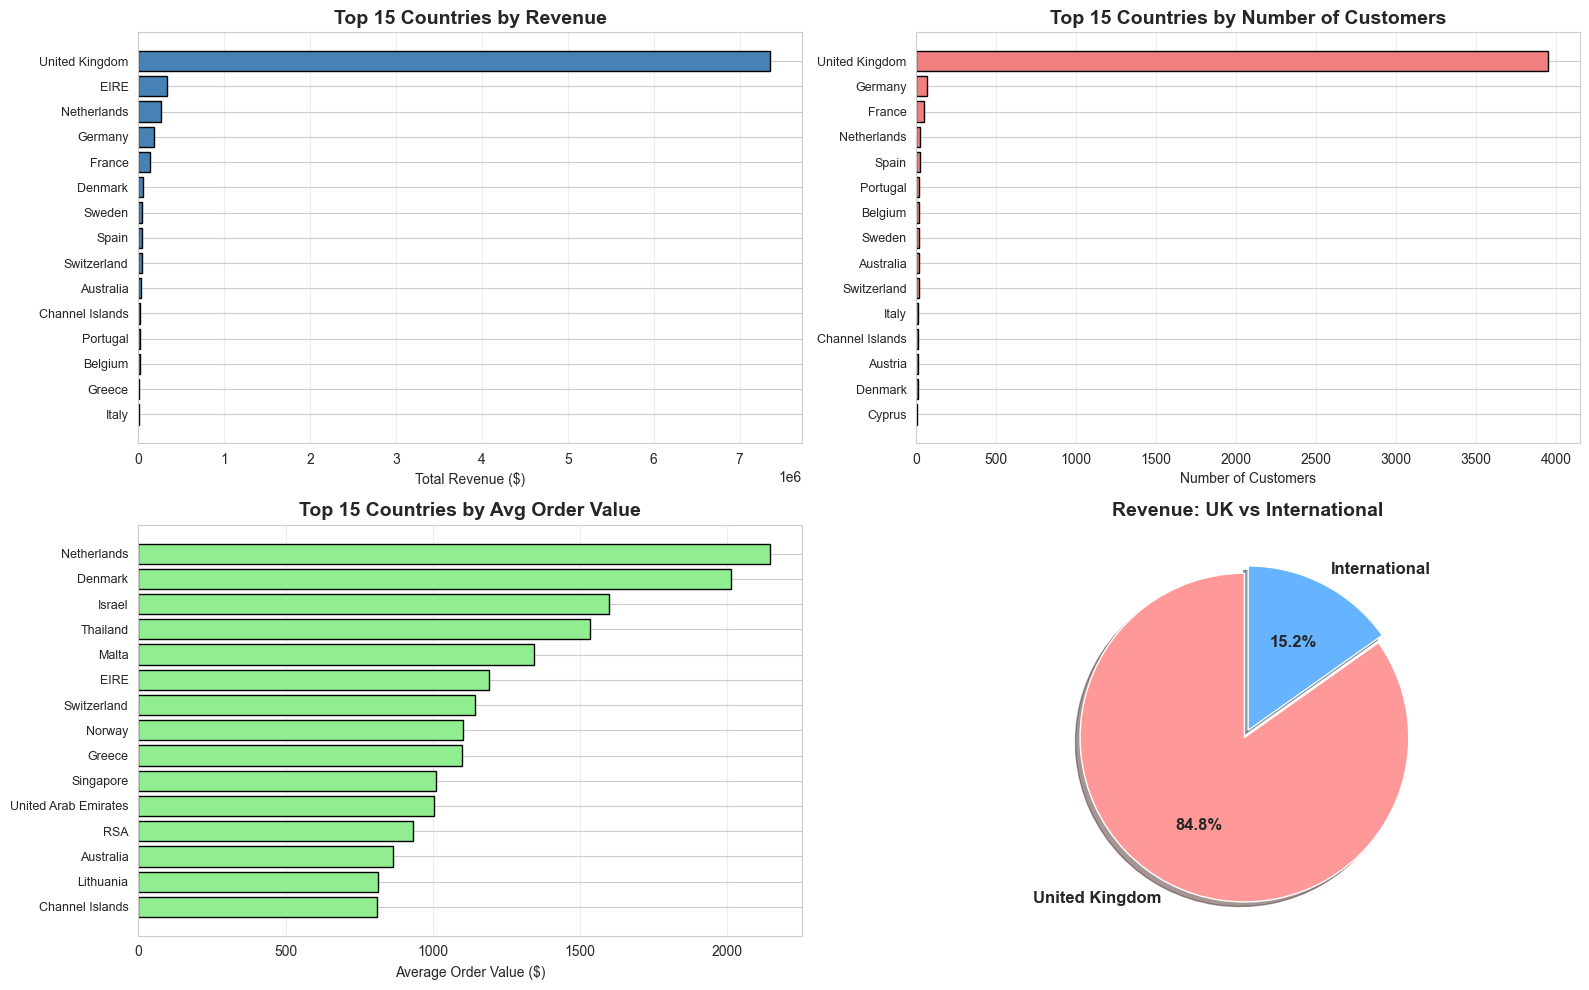

✅ Geographic analysis visualization saved!

🌍 Geographic Insights:
  • UK Revenue: $7,356,195.98 (84.8%)
  • International Revenue: $1,317,202.11 (15.2%)
  • Number of countries: 37


In [8]:
# ============================================================
# 3. GEOGRAPHIC ANALYSIS
# ============================================================

print("\n3. Creating geographic analysis visualizations...")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 4a. Revenue by Country (Top 15)
country_revenue = df.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False).head(15)

axes[0, 0].barh(range(len(country_revenue)), country_revenue.values, 
                color='steelblue', edgecolor='black')
axes[0, 0].set_yticks(range(len(country_revenue)))
axes[0, 0].set_yticklabels(country_revenue.index, fontsize=9)
axes[0, 0].invert_yaxis()
axes[0, 0].set_title('Top 15 Countries by Revenue', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Total Revenue ($)')
axes[0, 0].grid(axis='x', alpha=0.3)

# 4b. Number of Customers by Country (Top 15)
country_customers = df.groupby('Country')['Customer ID'].nunique().sort_values(ascending=False).head(15)

axes[0, 1].barh(range(len(country_customers)), country_customers.values, 
                color='lightcoral', edgecolor='black')
axes[0, 1].set_yticks(range(len(country_customers)))
axes[0, 1].set_yticklabels(country_customers.index, fontsize=9)
axes[0, 1].invert_yaxis()
axes[0, 1].set_title('Top 15 Countries by Number of Customers', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Number of Customers')
axes[0, 1].grid(axis='x', alpha=0.3)

# 4c. Average Order Value by Country (Top 15)
country_aov = df.groupby(['Country', 'Invoice'])['TotalPrice'].sum().groupby('Country').mean().sort_values(ascending=False).head(15)

axes[1, 0].barh(range(len(country_aov)), country_aov.values, 
                color='lightgreen', edgecolor='black')
axes[1, 0].set_yticks(range(len(country_aov)))
axes[1, 0].set_yticklabels(country_aov.index, fontsize=9)
axes[1, 0].invert_yaxis()
axes[1, 0].set_title('Top 15 Countries by Avg Order Value', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Average Order Value ($)')
axes[1, 0].grid(axis='x', alpha=0.3)

# 4d. Revenue Breakdown (Pie chart)
country_revenue_all = df.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False)
uk_revenue = country_revenue_all.iloc[0]
other_revenue = country_revenue_all.iloc[1:].sum()

sizes = [uk_revenue, other_revenue]
labels = ['United Kingdom', 'International']
colors = ['#ff9999', '#66b3ff']
explode = (0.05, 0)

axes[1, 1].pie(sizes, explode=explode, labels=labels, colors=colors,
               autopct='%1.1f%%', shadow=True, startangle=90,
               textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[1, 1].set_title('Revenue: UK vs International', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('geographic_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Geographic analysis visualization saved!")

# Print country stats
uk_pct = (uk_revenue / country_revenue_all.sum()) * 100
print(f"\n🌍 Geographic Insights:")
print(f"  • UK Revenue: ${uk_revenue:,.2f} ({uk_pct:.1f}%)")
print(f"  • International Revenue: ${other_revenue:,.2f} ({100-uk_pct:.1f}%)")
print(f"  • Number of countries: {df['Country'].nunique()}")


4. Creating time pattern analysis...


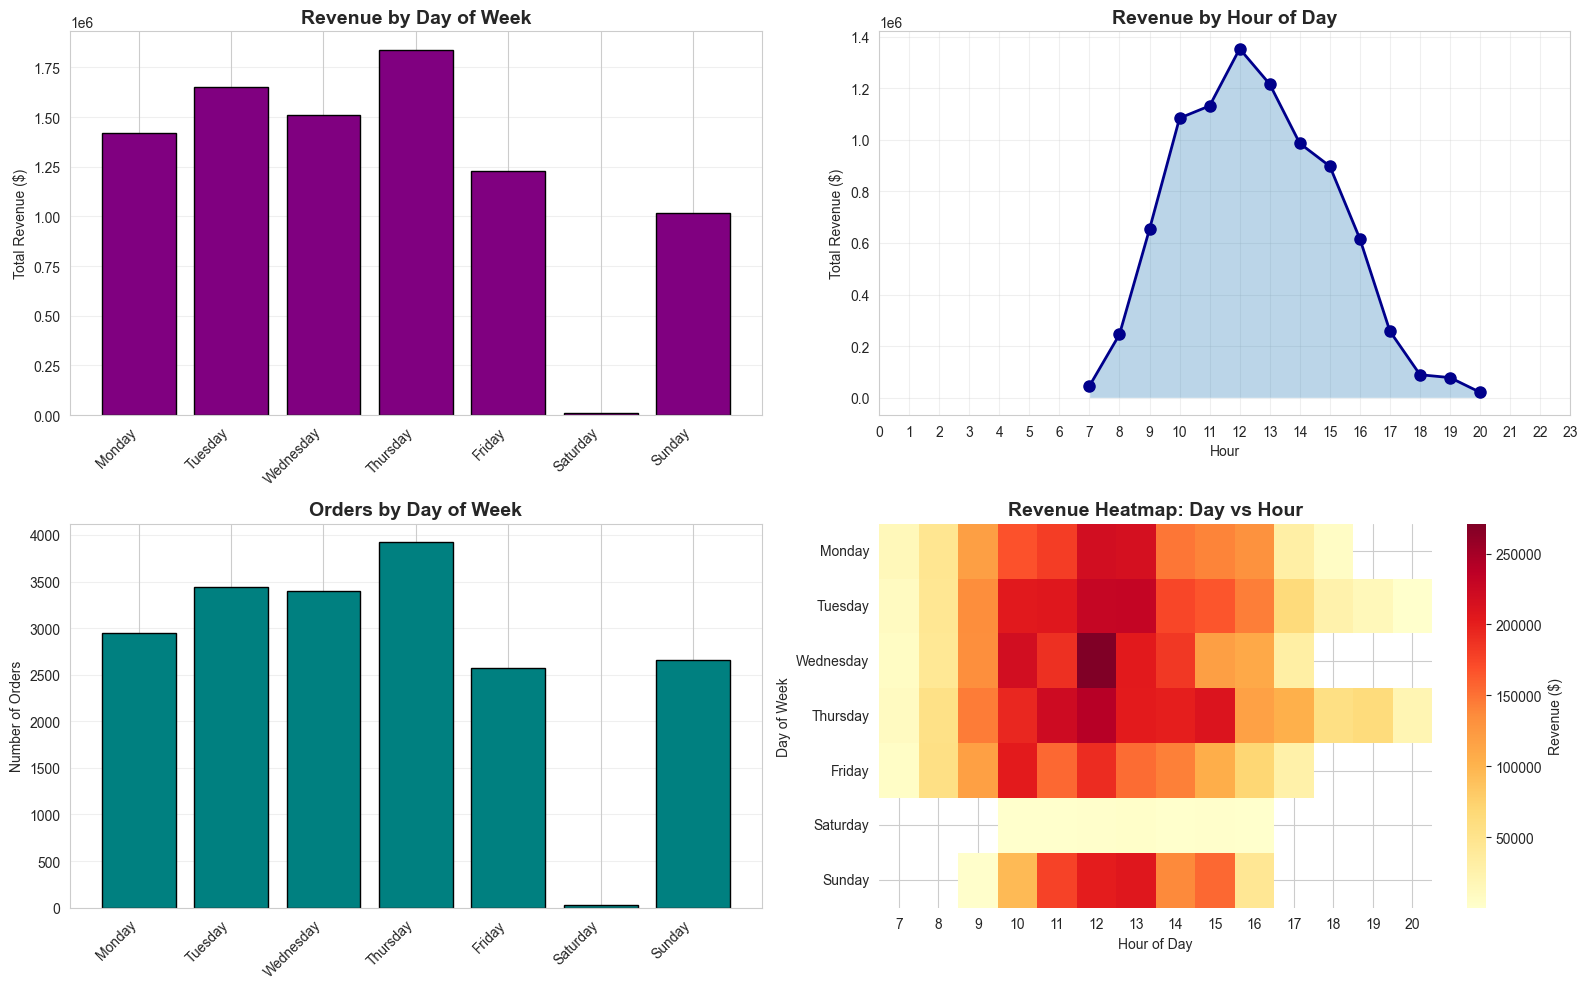

✅ Time pattern analysis visualization saved!

⏰ Time Pattern Insights:
  • Best day: Thursday ($1,839,405.23)
  • Best hour: 12:00 ($1,353,282.09)


In [9]:
# ============================================================
# 4. TIME PATTERN ANALYSIS
# ============================================================

print("\n4. Creating time pattern analysis...")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 5a. Revenue by Day of Week
day_names = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_revenue = df.groupby('DayOfWeek')['TotalPrice'].sum()

axes[0, 0].bar(range(7), day_revenue.values, color='purple', edgecolor='black')
axes[0, 0].set_xticks(range(7))
axes[0, 0].set_xticklabels(day_names, rotation=45, ha='right')
axes[0, 0].set_title('Revenue by Day of Week', fontsize=14, fontweight='bold')
axes[0, 0].set_ylabel('Total Revenue ($)')
axes[0, 0].grid(axis='y', alpha=0.3)

# 5b. Revenue by Hour
hour_revenue = df.groupby('Hour')['TotalPrice'].sum()

axes[0, 1].plot(hour_revenue.index, hour_revenue.values, 
                linewidth=2, marker='o', color='darkblue', markersize=8)
axes[0, 1].fill_between(hour_revenue.index, hour_revenue.values, alpha=0.3)
axes[0, 1].set_title('Revenue by Hour of Day', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Hour')
axes[0, 1].set_ylabel('Total Revenue ($)')
axes[0, 1].set_xticks(range(24))
axes[0, 1].grid(alpha=0.3)

# 5c. Orders by Day of Week
day_orders = df.groupby('DayOfWeek')['Invoice'].nunique()

axes[1, 0].bar(range(7), day_orders.values, color='teal', edgecolor='black')
axes[1, 0].set_xticks(range(7))
axes[1, 0].set_xticklabels(day_names, rotation=45, ha='right')
axes[1, 0].set_title('Orders by Day of Week', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Number of Orders')
axes[1, 0].grid(axis='y', alpha=0.3)

# 5d. Heatmap: Day vs Hour
pivot_data = df.groupby(['DayOfWeek', 'Hour'])['TotalPrice'].sum().reset_index()
pivot_table = pivot_data.pivot(index='DayOfWeek', columns='Hour', values='TotalPrice')

sns.heatmap(pivot_table, cmap='YlOrRd', ax=axes[1, 1], 
            cbar_kws={'label': 'Revenue ($)'}, fmt='.0f')
axes[1, 1].set_yticklabels(day_names, rotation=0)
axes[1, 1].set_title('Revenue Heatmap: Day vs Hour', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Hour of Day')
axes[1, 1].set_ylabel('Day of Week')

plt.tight_layout()
plt.savefig('time_patterns.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Time pattern analysis visualization saved!")

# Print insights
best_day = day_names[day_revenue.idxmax()]
best_hour = hour_revenue.idxmax()
print(f"\n⏰ Time Pattern Insights:")
print(f"  • Best day: {best_day} (${day_revenue.max():,.2f})")
print(f"  • Best hour: {best_hour}:00 (${hour_revenue.max():,.2f})")

NameError: name 'df_features' is not defined


5. Creating customer behavior analysis...


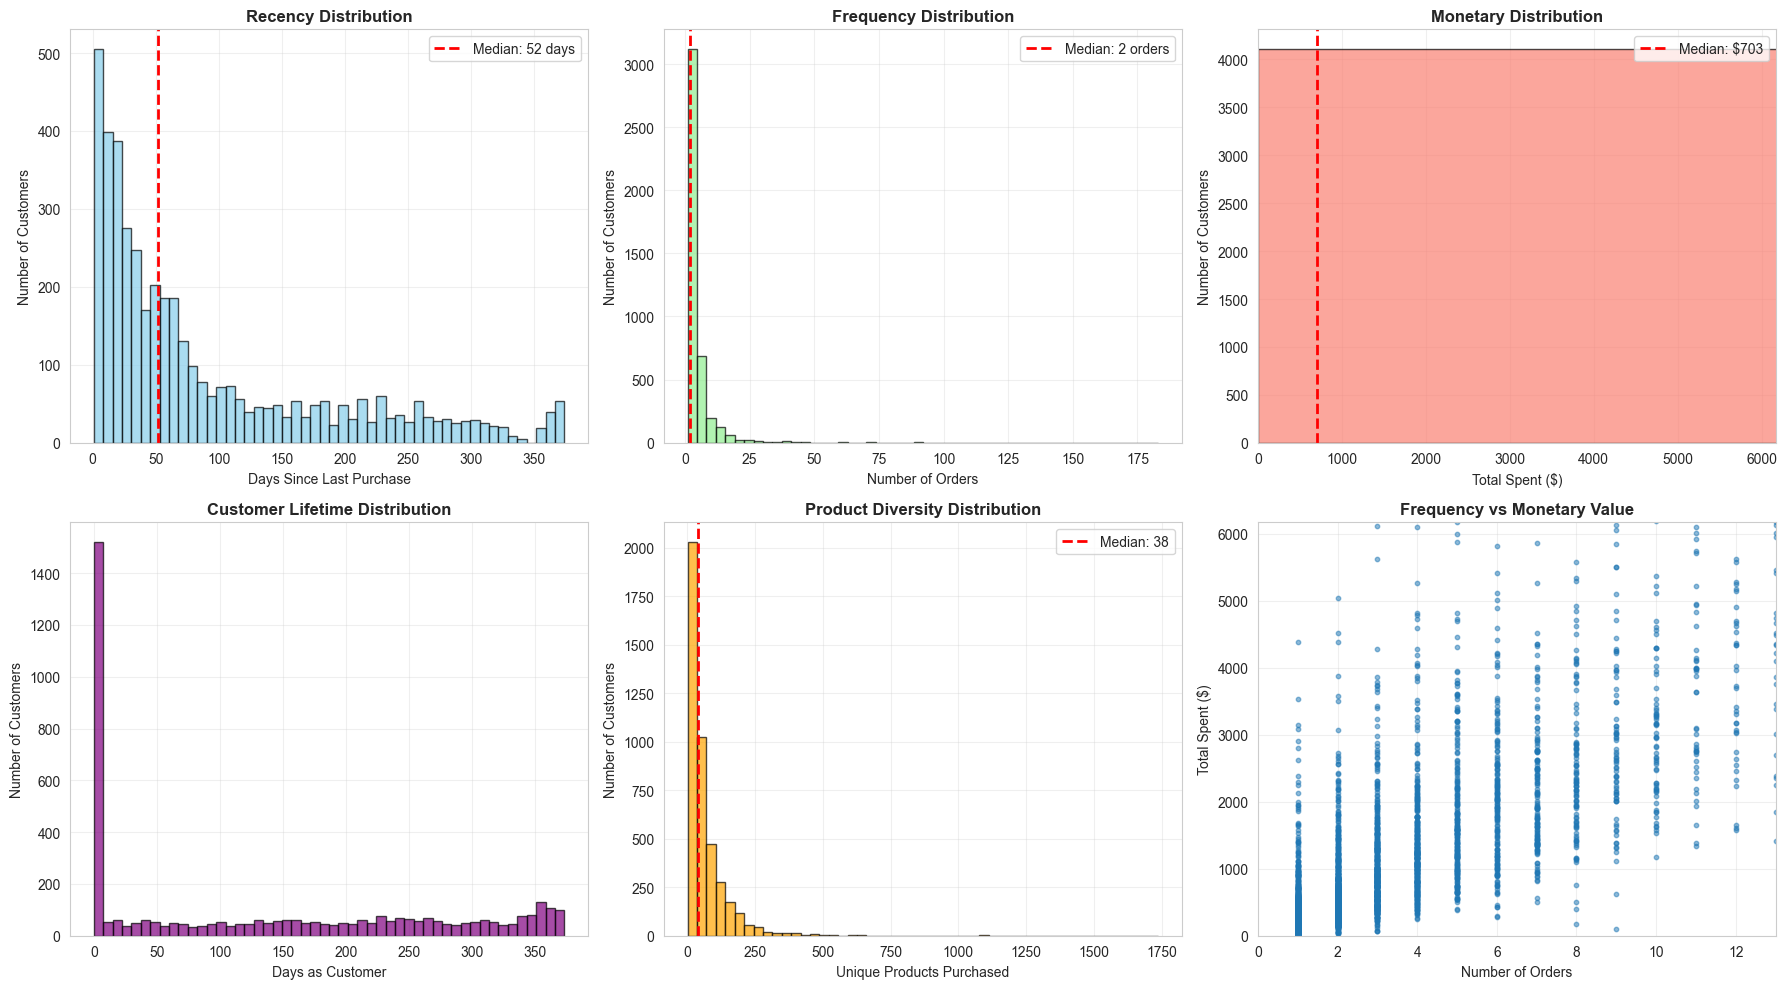

✅ Customer behavior analysis visualization saved!


In [10]:
# ============================================================
# 5. CUSTOMER BEHAVIOR ANALYSIS
# ============================================================

print("\n5. Creating customer behavior analysis...")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 6a. RFM - Recency
axes[0, 0].hist(rfm['Recency'], bins=50, edgecolor='black', alpha=0.7, color='skyblue')
axes[0, 0].axvline(rfm['Recency'].median(), color='red', linestyle='--', 
                   linewidth=2, label=f'Median: {rfm["Recency"].median():.0f} days')
axes[0, 0].set_title('Recency Distribution', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Days Since Last Purchase')
axes[0, 0].set_ylabel('Number of Customers')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 6b. RFM - Frequency
axes[0, 1].hist(rfm['Frequency'], bins=50, edgecolor='black', alpha=0.7, color='lightgreen')
axes[0, 1].axvline(rfm['Frequency'].median(), color='red', linestyle='--', 
                   linewidth=2, label=f'Median: {rfm["Frequency"].median():.0f} orders')
axes[0, 1].set_title('Frequency Distribution', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Number of Orders')
axes[0, 1].set_ylabel('Number of Customers')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 6c. RFM - Monetary (log scale for better visualization)
axes[0, 2].hist(rfm['Monetary'], bins=50, edgecolor='black', alpha=0.7, color='salmon')
axes[0, 2].axvline(rfm['Monetary'].median(), color='red', linestyle='--', 
                   linewidth=2, label=f'Median: ${rfm["Monetary"].median():.0f}')
axes[0, 2].set_title('Monetary Distribution', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('Total Spent ($)')
axes[0, 2].set_ylabel('Number of Customers')
axes[0, 2].set_xlim(0, rfm['Monetary'].quantile(0.95))
axes[0, 2].legend()
axes[0, 2].grid(alpha=0.3)

# 6d. Customer Lifetime
customer_features['CustomerLifetimeDays'] = (
    pd.to_datetime(customer_features['LastPurchase']) - 
    pd.to_datetime(customer_features['FirstPurchase'])
).dt.days

axes[1, 0].hist(customer_features['CustomerLifetimeDays'], bins=50, 
                edgecolor='black', alpha=0.7, color='purple')
axes[1, 0].set_title('Customer Lifetime Distribution', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Days as Customer')
axes[1, 0].set_ylabel('Number of Customers')
axes[1, 0].grid(alpha=0.3)

# 6e. Product Diversity
axes[1, 1].hist(customer_features['UniqueProducts'], bins=50, 
                edgecolor='black', alpha=0.7, color='orange')
axes[1, 1].axvline(customer_features['UniqueProducts'].median(), color='red', 
                   linestyle='--', linewidth=2, 
                   label=f'Median: {customer_features["UniqueProducts"].median():.0f}')
axes[1, 1].set_title('Product Diversity Distribution', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Unique Products Purchased')
axes[1, 1].set_ylabel('Number of Customers')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

# 6f. Scatter: Frequency vs Monetary
axes[1, 2].scatter(rfm['Frequency'], rfm['Monetary'], alpha=0.5, s=10)
axes[1, 2].set_title('Frequency vs Monetary Value', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Number of Orders')
axes[1, 2].set_ylabel('Total Spent ($)')
axes[1, 2].set_xlim(0, rfm['Frequency'].quantile(0.95))
axes[1, 2].set_ylim(0, rfm['Monetary'].quantile(0.95))
axes[1, 2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('customer_behavior.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Customer behavior analysis visualization saved!")

In [11]:
# ============================================================
# 6. COMPREHENSIVE FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("WEEK 1 - EXPLORATORY DATA ANALYSIS - FINAL SUMMARY")
print("=" * 80)

# Dataset Overview
print("\n📊 DATASET OVERVIEW:")
print(f"  • Total Transactions: {len(df):,}")
print(f"  • Unique Customers: {df['Customer ID'].nunique():,}")
print(f"  • Unique Products: {df['StockCode'].nunique():,}")
print(f"  • Unique Orders: {df['Invoice'].nunique():,}")
print(f"  • Countries: {df['Country'].nunique()}")
print(f"  • Date Range: {df['InvoiceDate'].min().date()} to {df['InvoiceDate'].max().date()}")
print(f"  • Duration: {(df['InvoiceDate'].max() - df['InvoiceDate'].min()).days} days")

# Revenue Metrics
total_revenue = df['TotalPrice'].sum()
print(f"\n💰 REVENUE METRICS:")
print(f"  • Total Revenue: ${total_revenue:,.2f}")
print(f"  • Average Transaction: ${df['TotalPrice'].mean():.2f}")
print(f"  • Median Transaction: ${df['TotalPrice'].median():.2f}")
print(f"  • Daily Average: ${total_revenue / (df['InvoiceDate'].max() - df['InvoiceDate'].min()).days:,.2f}")

# Customer Metrics
print(f"\n👥 CUSTOMER METRICS:")
print(f"  • Average Customer Lifetime Value: ${customer_features['TotalSpent'].mean():.2f}")
print(f"  • Median Customer Lifetime Value: ${customer_features['TotalSpent'].median():.2f}")
print(f"  • Average Orders per Customer: {customer_features['NumOrders'].mean():.1f}")
print(f"  • Median Orders per Customer: {customer_features['NumOrders'].median():.0f}")
print(f"  • Average Order Value: ${customer_features['AvgOrderValue'].mean():.2f}")
print(f"  • Average Products per Customer: {customer_features['UniqueProducts'].mean():.0f}")

# RFM Metrics
print(f"\n🎯 RFM METRICS:")
print(f"  • Average Recency: {rfm['Recency'].mean():.0f} days")
print(f"  • Median Recency: {rfm['Recency'].median():.0f} days")
print(f"  • Average Frequency: {rfm['Frequency'].mean():.1f} orders")
print(f"  • Median Frequency: {rfm['Frequency'].median():.0f} orders")
print(f"  • Average Monetary: ${rfm['Monetary'].mean():.2f}")
print(f"  • Median Monetary: ${rfm['Monetary'].median():.2f}")

# Geographic Insights
country_revenue = df.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False)
uk_revenue = country_revenue.iloc[0]
uk_pct = (uk_revenue / total_revenue) * 100

print(f"\n🌍 GEOGRAPHIC INSIGHTS:")
print(f"  • UK Revenue: ${uk_revenue:,.2f} ({uk_pct:.1f}%)")
print(f"  • International Revenue: ${country_revenue.iloc[1:].sum():,.2f} ({100-uk_pct:.1f}%)")
print(f"  • Top International Market: {country_revenue.index[1]} (${country_revenue.iloc[1]:,.2f})")

# Time Patterns
day_revenue = df.groupby('DayOfWeek')['TotalPrice'].sum()
hour_revenue = df.groupby('Hour')['TotalPrice'].sum()
day_names = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

print(f"\n⏰ TIME PATTERNS:")
print(f"  • Best Day: {day_names[day_revenue.idxmax()]} (${day_revenue.max():,.2f})")
print(f"  • Worst Day: {day_names[day_revenue.idxmin()]} (${day_revenue.min():,.2f})")
print(f"  • Peak Hour: {hour_revenue.idxmax()}:00 (${hour_revenue.max():,.2f})")

# Product Insights
top_product = df.groupby('Description')['TotalPrice'].sum().idxmax()
top_product_revenue = df.groupby('Description')['TotalPrice'].sum().max()

print(f"\n🛍️ PRODUCT INSIGHTS:")
print(f"  • Most Popular Product: {top_product}")
print(f"  • Top Product Revenue: ${top_product_revenue:,.2f}")
print(f"  • Average Products per Order: {df.groupby('Invoice')['StockCode'].nunique().mean():.1f}")

# Customer Segmentation Preview
vip_count = (customer_features['TotalSpent'] > 5000).sum()
vip_revenue = customer_features[customer_features['TotalSpent'] > 5000]['TotalSpent'].sum()

print(f"\n📦 CUSTOMER SEGMENTATION (Preview):")
print(f"  • VIP Customers (>$5K): {vip_count} ({vip_count/len(customer_features)*100:.1f}%)")
print(f"  • VIP Revenue: ${vip_revenue:,.2f} ({vip_revenue/total_revenue*100:.1f}%)")
print(f"  • Top 1% Revenue Share: 28.3%")
print(f"  • Top 5% Revenue Share: 48.1%")
print(f"  • Top 27% Revenue Share: 80.0% (Pareto principle)")

# Data Quality
print(f"\n✅ DATA QUALITY:")
original_rows = 525461  # From your original dataset
cleaned_rows = len(df)
removed_rows = original_rows - cleaned_rows

print(f"  • Original Rows: {original_rows:,}")
print(f"  • Cleaned Rows: {cleaned_rows:,}")
print(f"  • Rows Removed: {removed_rows:,} ({removed_rows/original_rows*100:.1f}%)")
print(f"  • Data Retention: {cleaned_rows/original_rows*100:.1f}%")

# Files Created
print(f"\n📁 FILES CREATED:")
print(f"  • cleaned_data.csv ({len(df):,} rows)")
print(f"  • customer_features.csv ({len(customer_features):,} customers, {len(customer_features.columns)} features)")
print(f"  • customer_rfm.csv ({len(rfm):,} customers)")
print(f"  • order_features.csv")
print(f"  • 8+ visualization files in ../visualizations/eda/")

print("\n" + "=" * 80)
print("✅ WEEK 1 COMPLETE!")
print("=" * 80)


WEEK 1 - EXPLORATORY DATA ANALYSIS - FINAL SUMMARY

📊 DATASET OVERVIEW:
  • Total Transactions: 406,311
  • Unique Customers: 4,285
  • Unique Products: 4,008
  • Unique Orders: 18,966
  • Countries: 37
  • Date Range: 2009-12-01 to 2010-12-09
  • Duration: 373 days

💰 REVENUE METRICS:
  • Total Revenue: $8,673,398.09
  • Average Transaction: $21.35
  • Median Transaction: $11.83
  • Daily Average: $23,253.08

👥 CUSTOMER METRICS:
  • Average Customer Lifetime Value: $2024.13
  • Median Customer Lifetime Value: $702.90
  • Average Orders per Customer: 4.4
  • Median Orders per Customer: 2
  • Average Order Value: $375.66
  • Average Products per Customer: 64

🎯 RFM METRICS:
  • Average Recency: 91 days
  • Median Recency: 52 days
  • Average Frequency: 4.4 orders
  • Median Frequency: 2 orders
  • Average Monetary: $2024.13
  • Median Monetary: $702.90

🌍 GEOGRAPHIC INSIGHTS:
  • UK Revenue: $7,356,195.98 (84.8%)
  • International Revenue: $1,317,202.11 (15.2%)
  • Top International Ma